# Lab 5: The SIR Epidemic Model

**Homework 4 (Module 1 · deterministic ODE — population modeling)** · *Kermack–McKendrick* · **Hao-Tian Jin** · 2026-10-03

This notebook studies the **SIR model** of an epidemic in four parts:

1. **Model & numerical simulation** — the equations, the parameters $\beta,\gamma$, and a baseline run;
2. **Parameter / phase space & trajectories** — an interactive widget to move $\beta,\gamma$ by hand and
   watch the epidemic curve and the $(S,I)$ phase trajectory respond;
3. **Stability analysis** — where the reproduction number $R_0=\beta/\gamma$ comes from, via the linear
   stability of the disease-free equilibrium;
4. **Summary**.

> **Parameter note.** The numbers below ($\beta,\gamma$ in $\mathrm{day}^{-1}$) are standard textbook
> placeholders for a generic infection, **not** fitted to real data. Only the ratio $R_0=\beta/\gamma$
> carries the biology; the absolute time scale is set by $\beta,\gamma$ together.


---

# Part 1 · Model and numerical simulation

A closed population of $N$ people is split into **S**usceptible, **I**nfectious, **R**ecovered, with
$S+I+R=N$ and $S,I,R\ge 0$. The SIR equations are

$$
\begin{aligned}
\frac{\mathrm dS}{\mathrm dt} &= -\beta\,\frac{S I}{N}, \\[2pt]
\frac{\mathrm dI}{\mathrm dt} &= +\beta\,\frac{S I}{N} - \gamma\,I, \\[2pt]
\frac{\mathrm dR}{\mathrm dt} &= +\gamma\,I .
\end{aligned}
$$

* **Transmission** $\beta SI/N$: a susceptible meets an infectious person at rate $\propto SI$ (homogeneous
  mass-action mixing); $\beta$ is the **transmission rate**.
* **Recovery** $\gamma I$: an infectious person recovers at rate $\gamma$ (mean infectious period $=1/\gamma$).
* **Conservation:** $\dot S+\dot I+\dot R=0$, so $N$ is preserved (a solver check).
* **$R_0=\beta/\gamma$** is the average number of secondary infections caused by one infectious person in a
  fully susceptible population; it decides everything (Parts 2–3).

We solve the ODE numerically with `solve_ivp` and read off the classic shape.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq
import ipywidgets as widgets
from IPython.display import display, clear_output

def sir(t, y, beta, gamma, N):
    S, I, R = y
    return [-beta*S*I/N,
             beta*S*I/N - gamma*I,
             gamma*I]

def run_sir(beta, gamma, N=1000., I0=5, t_max=160, n=801):
    y0 = [N-I0, I0, 0.0]
    t_eval = np.linspace(0, t_max, n)
    sol = solve_ivp(sir, (0, t_max), y0, args=(beta, gamma, N),
                    t_eval=t_eval, rtol=1e-8, atol=1e-10)
    return sol.t, sol.y[0], sol.y[1], sol.y[2]

N = 1000.0
beta0, gamma0 = 0.50, 0.10          # R0 = 5 : fast, moderately long illness
tb, Sb, Ib, Rb = run_sir(beta0, gamma0, N=N)
print(f"Baseline  beta={beta0}, gamma={gamma0}  ->  R0 = {beta0/gamma0:.1f}")
print(f"Peak infected {Ib.max():.0f} at t = {tb[np.argmax(Ib)]:.1f} d   "
      f"final size {(N-Sb[-1])/N*100:.1f}%   S+I+R = {Sb[-1]+Ib[-1]+Rb[-1]:.1f}")

Baseline  beta=0.5, gamma=0.1  ->  R0 = 5.0
Peak infected 479 at t = 17.2 d   final size 99.3%   S+I+R = 1000.0


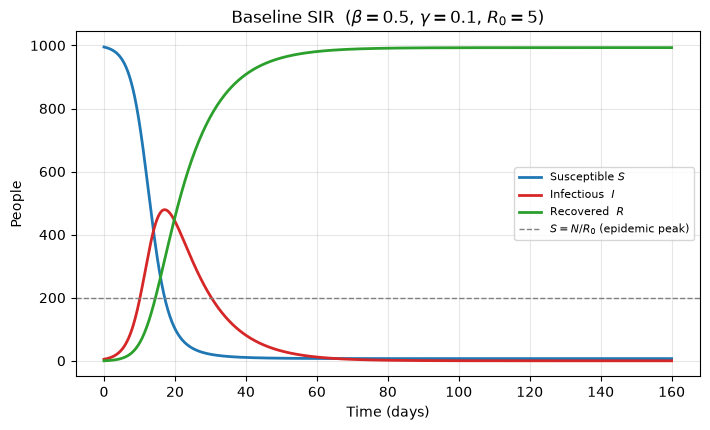

In [2]:
# Baseline S/I/R curves
fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.plot(tb, Sb, lw=2, color='tab:blue',  label='Susceptible $S$')
ax.plot(tb, Ib, lw=2, color='tab:red',   label='Infectious  $I$')
ax.plot(tb, Rb, lw=2, color='tab:green', label='Recovered  $R$')
ax.axhline(N/(beta0/gamma0), color='gray', ls='--', lw=1, label=r'$S=N/R_0$ (epidemic peak)')
ax.set_xlabel('Time (days)'); ax.set_ylabel('People')
ax.set_title(fr'Baseline SIR  ($\beta={beta0}$, $\gamma={gamma0}$, $R_0={beta0/gamma0:.0f}$)')
ax.legend(fontsize=8); ax.grid(alpha=0.3); fig.tight_layout(); plt.show()

---

# Part 2 · Parameter / phase space and trajectories

Interactive widgets let us move $\\beta$ and $\\gamma$ by hand and watch the model respond; dragging a slider redraws the figures immediately.

Two views are shown together:
* **left — time courses** $S,I,R$ (the epidemic curve);
* **right — phase trajectory** in the $(S,I)$ plane: the curve starts at $(N-I_0,\,I_0)$ and runs to
  $(S_\infty,0)$ as the epidemic plays out. For $R_0>1$ it first rises then falls back to the $S$-axis
  (the "hump"); for $R_0<1$ it decays straight back with no hump.

**Try it:** raise $\beta$ or lower $\gamma$ (both raise $R_0=\beta/\gamma$) — the peak moves up and earlier
and the phase hump grows. Push $R_0$ below 1 and the epidemic disappears entirely.


interactive(children=(FloatSlider(value=0.5, continuous_update=False, description='β (transmission)', max=1.0,…

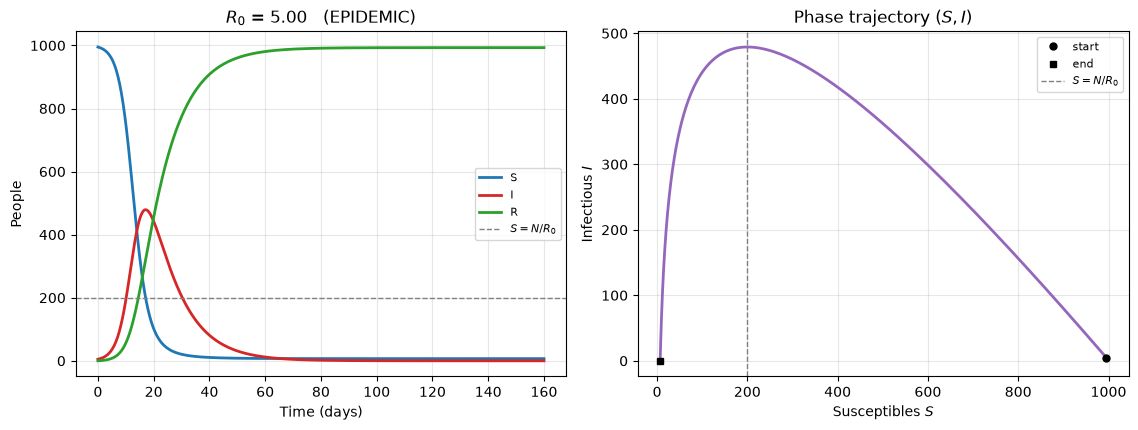

In [ ]:
# Interactive SIR widgets via interact(): dragging the sliders redraws S, I, R
# and the (S, I) phase trajectory live.
from ipywidgets import interact

def draw(beta, gamma):
    t, S, I, R = run_sir(beta, gamma, N=N)
    R0 = beta / gamma
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.4))

    ax1.plot(t, S, lw=2, color='tab:blue',  label='S')
    ax1.plot(t, I, lw=2, color='tab:red',   label='I')
    ax1.plot(t, R, lw=2, color='tab:green', label='R')
    if R0 > 1:
        ax1.axhline(N/R0, color='gray', ls='--', lw=1, label=r'$S=N/R_0$')
    ax1.set_xlabel('Time (days)'); ax1.set_ylabel('People'); ax1.grid(alpha=0.3)
    ax1.legend(fontsize=8)
    ax1.set_title(fr'$R_0$ = {R0:.2f}   ({"EPIDEMIC" if R0>1 else "no epidemic"})')

    ax2.plot(S, I, lw=2, color='tab:purple')
    ax2.plot(S[0], I[0], 'o', color='black', ms=5, label='start')
    ax2.plot(S[-1], I[-1], 's', color='black', ms=5, label='end')
    if R0 > 1:
        ax2.axvline(N/R0, color='gray', ls='--', lw=1, label=r'$S=N/R_0$')
    ax2.set_xlabel('Susceptibles $S$'); ax2.set_ylabel('Infectious $I$')
    ax2.grid(alpha=0.3); ax2.legend(fontsize=8)
    ax2.set_title('Phase trajectory $(S,I)$')

    fig.tight_layout(); plt.show()

interact(draw,
         beta=widgets.FloatSlider(value=0.50, min=0.05, max=1.00, step=0.01,
                                  description='β (transmission)',
                                  continuous_update=False, readout_format=".2f"),
         gamma=widgets.FloatSlider(value=0.10, min=0.05, max=0.60, step=0.01,
                                   description='γ (recovery)',
                                   continuous_update=False, readout_format=".2f"));
draw(0.50, 0.10)   # static fallback (visible in a plain / headless view too)

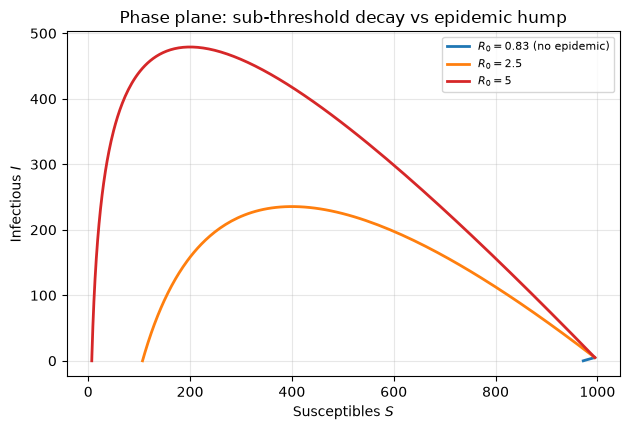

In [4]:
# Static version of the phase plane for several R0 (visible even without widgets)
fig, ax = plt.subplots(figsize=(6.4, 4.4))
for b, g, lab, col in [(0.50, 0.60, r'$R_0=0.83$ (no epidemic)', 'tab:blue'),
                       (0.50, 0.20, r'$R_0=2.5$', 'tab:orange'),
                       (0.50, 0.10, r'$R_0=5$', 'tab:red')]:
    t, S, I, R = run_sir(b, g, N=N)
    ax.plot(S, I, lw=2, color=col, label=lab)
ax.set_xlabel(r'Susceptibles $S$'); ax.set_ylabel(r'Infectious $I$')
ax.set_title('Phase plane: sub-threshold decay vs epidemic hump')
ax.legend(fontsize=8); ax.grid(alpha=0.3); fig.tight_layout(); plt.show()

---

# Part 3 · Stability analysis: where $R_0=1$ comes from

Since $R=N-S-I$, the effective system is
$$
\dot S = -\beta\,\frac{SI}{N}, \qquad
\dot I = \beta\,\frac{SI}{N} - \gamma\,I .
$$

**Equilibria.** Setting $\dot S=\dot I=0$ forces $I=0$: the only fixed points are the *disease-free
equilibria* $(S^*,0)$, in particular $(N,0)$.

**Linear stability of $(N,0)$.** The Jacobian is
$$
J(N,0)=
\begin{pmatrix}
\partial_S\dot S & \partial_I\dot S\\
\partial_S\dot I & \partial_I\dot I
\end{pmatrix}_{(N,0)}
=
\begin{pmatrix}
0 & -\beta\\
0 & \beta-\gamma
\end{pmatrix},
\qquad
\lambda\in\{0,\ \beta-\gamma\}.
$$
The $S$-direction is neutral; the disease-relevant eigenvalue is
$$
\lambda=\beta-\gamma=\gamma(R_0-1).
$$
* $R_0<1\Rightarrow\lambda<0$: $(N,0)$ is **linearly stable** — no epidemic.
* $R_0>1\Rightarrow\lambda>0$: $(N,0)$ is **unstable** — epidemic.
* $R_0=1$: the threshold.

**Final size.** On a trajectory, $dS/dR=-R_0 S/N$, separable to $\ln(S/S_\infty)=R_0(S-S_\infty)/N$. With
$f=1-S_\infty/N$ the fraction ever infected,
$$
f = 1 - e^{-R_0 f},
$$
which has a positive solution iff $R_0>1$. Both results are verified numerically below.


In [5]:
# (a) eigenvalue threshold vs R0, and a seeded-infection sanity check
import pandas as pd
from IPython.display import display

rows = []
for b, g in [(0.50, 0.60), (0.50, 0.55), (0.50, 0.50), (0.50, 0.35), (0.50, 0.20), (0.50, 0.10)]:
    lam = b - g
    rows.append({"beta": b, "gamma": g, "R0": b/g, "lambda (=beta-gamma)": lam,
                 "epidemic?": "YES" if lam > 0 else "NO"})
display(pd.DataFrame(rows))

print("\nSeed a few infectives and watch the first step:")
srows = []
for b, g in [(0.50, 0.60), (0.50, 0.10)]:
    t, S, I, R = run_sir(b, g, N=N, I0=10)
    i3 = np.searchsorted(t, 3.0)          # index of the t ~ 3 d point
    srows.append({"R0": b/g, "I(0)": f"{I[0]:.0f}", "I(~3d)": f"{I[i3]:.0f}",
                  "behaviour": "decays" if I[i3] < I[0] else "grows"})
display(pd.DataFrame(srows))

,beta,gamma,R0,lambda (=beta-gamma),epidemic?
0,0.5,0.60,0.833333,-0.10,NO
1,0.5,0.55,0.909091,-0.05,NO
2,0.5,0.50,1.000000,0.00,NO
3,0.5,0.35,1.428571,0.15,YES
4,0.5,0.20,2.500000,0.30,YES
5,0.5,0.10,5.000000,0.40,YES



Seed a few infectives and watch the first step:


,R0,I(0),I(~3d),behaviour
0,0.833333,10,7,decays
1,5.000000,10,32,grows


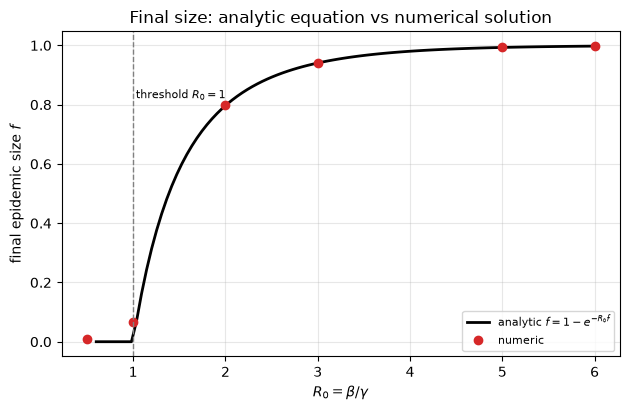

Numeric final sizes sit exactly on the analytic final-size curve.


In [6]:
# (b) final-size curve: analytic f = 1 - exp(-R0 f) vs numerics
def f_an(R0):
    return 0.0 if R0 <= 1 else brentq(lambda f: f - (1 - np.exp(-R0*f)), 1e-12, 1.0-1e-12)

R0s = np.linspace(0.6, 6.0, 100)
fa = np.array([f_an(r) for r in R0s])
fn, rn = [], []
for b in [0.05, 0.10, 0.20, 0.30, 0.50, 0.60]:
    t, S, I, R = run_sir(b, 0.10, N=N)
    rn.append(b/0.10); fn.append((N - S[-1])/N)

fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(R0s, fa, color='black', lw=2, label=r'analytic $f=1-e^{-R_0 f}$')
ax.plot(rn, fn, 'o', color='tab:red', ms=6, label='numeric')
ax.axvline(1.0, color='gray', ls='--', lw=1)
ax.text(1.03, 0.82, r'threshold $R_0=1$', fontsize=8)
ax.set_xlabel(r'$R_0=\beta/\gamma$'); ax.set_ylabel(r'final epidemic size $f$')
ax.set_title('Final size: analytic equation vs numerical solution')
ax.legend(fontsize=8); ax.grid(alpha=0.3); fig.tight_layout(); plt.show()

print("Numeric final sizes sit exactly on the analytic final-size curve.")

---

# Part 4 · Summary

**What we did.** We built and solved the SIR model, explored its parameter/phase space with an
interactive slider widget (and a static phase-plane view), and performed the stability analysis.

**The single message: everything is controlled by $R_0=\beta/\gamma$.**
1. **Threshold.** Linearising the disease-free equilibrium $(N,0)$ gives eigenvalue
   $\lambda=\beta-\gamma=\gamma(R_0-1)$. The state is stable (no epidemic) iff $R_0\le 1$; we confirmed the
   sign change at $R_0=1$ both from the Jacobian and from the seeded-infection sanity check.
2. **Magnitude.** Raising $R_0$ (raising $\beta$ or lowering $\gamma$) makes the epidemic peak higher and
   earlier and increases the final fraction ever infected, given by $f=1-e^{-R_0 f}$ (positive only for
   $R_0>1$; our numerical final sizes match it exactly).
3. **Why it stops early.** The epidemic ends because infectives run out of susceptibles, not because the
   pathogen disappears — the peak of $I$ occurs at the herd-immunity level $S=N/R_0$.

**Which parameter matters?** In the phase/parameter-space exploration, moving $\beta$ or $\gamma$ produces
qualitatively the *same* family of curves once they are relabelled by $R_0$ — the two parameters enter only
through their ratio. This is exactly why public-health measures aim to push the *effective* reproduction
number below 1 (reduce $\beta$ via masks/distancing/vaccination, or raise $\gamma$ via isolation/treatment).

**Limitations.** The model is deliberately minimal: no births/deaths or waning immunity (so the only
equilibrium here is the disease-free one), homogeneous mixing (no age structure, geography, or
superspreading), exponentially distributed infectious period (no latent SEIR stage), and illustrative rather
than data-fitted parameters. The threshold phenomenon, the shape of the epidemic curve, and the bounded
final size are, however, structural and survive in far richer models.
